<a href="https://colab.research.google.com/github/agugun/axscnt-notebook/blob/main/vector_calculus/Vector_Calculus_Integral.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Integral Vector Calculus

Integrals **add up** a field's contributions along a curve, over a surface, or through a volume. Every section uses the same layout:

- **INPUT**: the field and the curve / surface / region
- **PROCESS**: the parameterisation and the integrand that is summed
- **OUTPUT**: the accumulated result, checked against the exact value

| # | Integral | Formula | Measures |
|---|---|---|---|
| 1 | Line integral: work | $\int_C \mathbf F\cdot d\mathbf r$ | energy transferred by $\mathbf F$ moving along $C$ |
| 1 | Line integral: circulation | $\oint_C \mathbf F\cdot d\mathbf r$ | how much $\mathbf F$ flows around a closed loop |
| 2 | Surface integral: flux | $\iint_S \mathbf F\cdot\hat{\mathbf n}\, dS$ | net flow of $\mathbf F$ through a surface |
| 3 | Volume integral | $\iiint_E \rho\, dV$ | total amount (mass, charge, ...) in a region |
| 4 | Path independence | $\int_C \nabla\varphi\cdot d\mathbf r = \varphi(B) - \varphi(A)$ | when work depends only on the end points |
| 5 | Integral theorems | Green, Stokes, Divergence | how these integrals connect to the derivatives in `Vector_Calculus_Differential.ipynb` |

Sections 2, 3 and 5 share one solid: the region under the paraboloid $z = 1 - x^2 - y^2$, $z \ge 0$.

## 1. Line Integrals: Work and Circulation

Parameterise the curve as $\mathbf r(t)$, $a \le t \le b$. Then $d\mathbf r = \mathbf r'(t)\,dt$ and

$$W = \int_C \mathbf F\cdot d\mathbf r = \int_a^b \mathbf F(\mathbf r(t))\cdot\mathbf r'(t)\, dt$$

Only the component of $\mathbf F$ **along** the curve counts: where $\mathbf F$ pushes along the direction of travel the integrand is positive, where it pushes against it the integrand is negative.

For a **closed** curve the same integral is called the **circulation** $\oint_C \mathbf F\cdot d\mathbf r$.

Example field: $\mathbf F = (x - y,\ x + y)$, a rotation $(-y, x)$ plus an expansion $(x, y)$.
- **Work** along the parabola $\mathbf r(t) = (t,\ t^2/2 - 1)$, $-2 \le t \le 2$. Exact: $\int_{-2}^{2} \left(\tfrac{t^3}{2} + \tfrac{t^2}{2} + 1\right) dt = \tfrac{20}{3}$.
- **Circulation** around the ellipse $\mathbf r(t) = (2\cos t,\ 1.2\sin t)$. The expansion part adds nothing around a closed loop. The rotation part gives $2 \times \text{area} = 2\pi(2)(1.2)$, which is Green's theorem (section 5).

--- LINE INTEGRALS ---
Work        W = 6.666675   exact 20/3     = 6.666667   error 8.3e-06
Circulation   = 15.079645   exact 2*pi*a*b = 15.079645   error 7.1e-15
  from rotation part  (-y, x): 15.079645
  from expansion part ( x, y): 1.37e-15


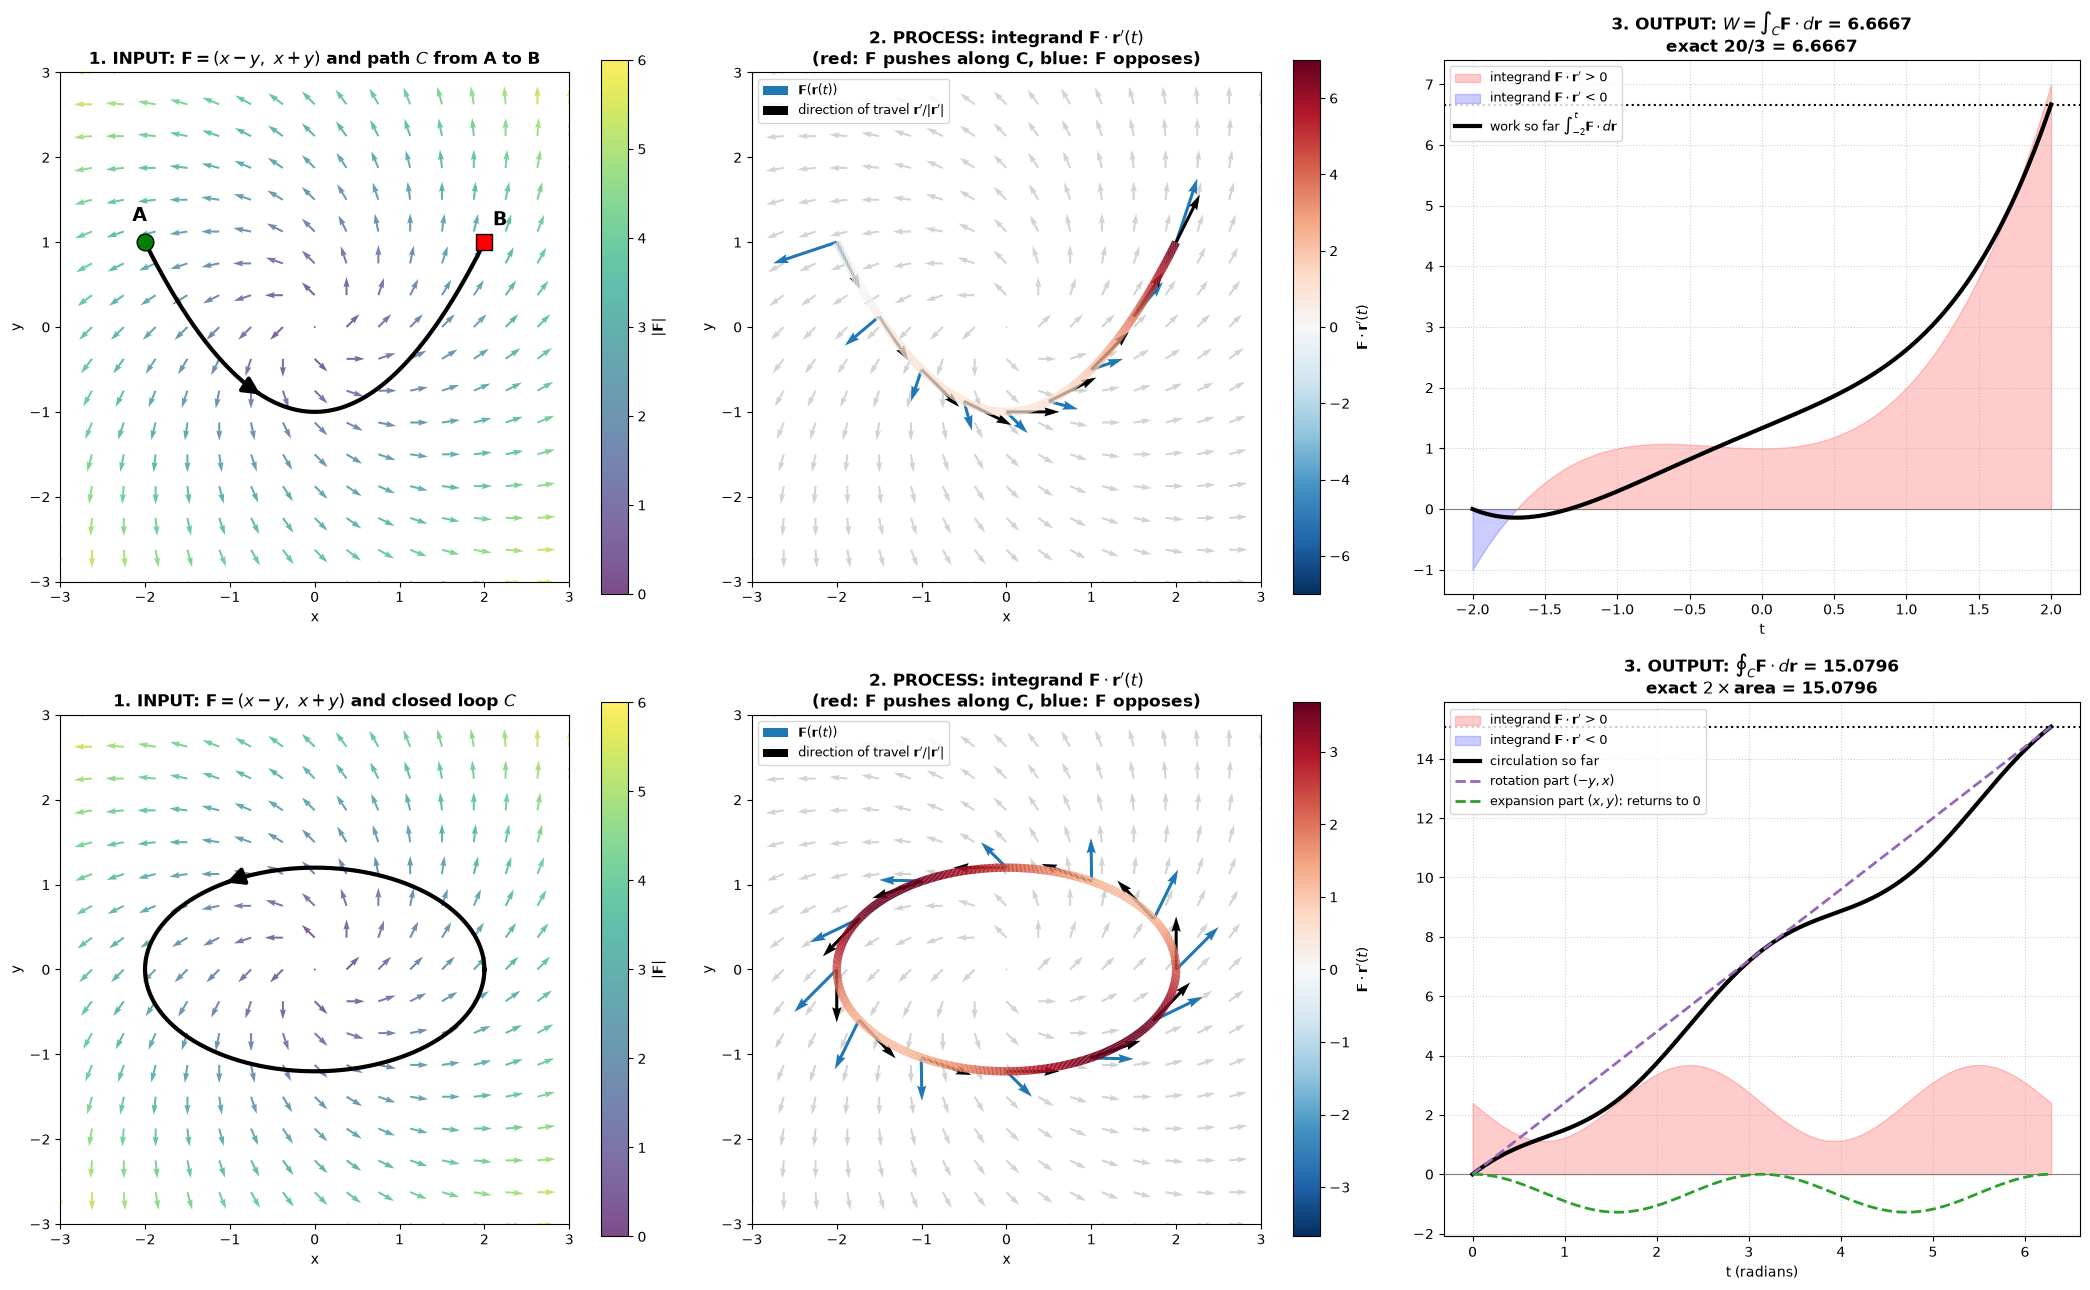

In [1]:
# 1. LINE INTEGRALS: work along an open curve, circulation around a closed curve
# INPUT: F and C  ->  PROCESS: F(r(t)) . r'(t) along C  ->  OUTPUT: accumulated integral

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import TwoSlopeNorm


def F(x, y):
    return x - y, x + y          # rotation (-y, x) + expansion (x, y)


def cumtrap(fv, t):
    # Cumulative trapezoid integral, starting at 0
    return np.concatenate([[0.0], np.cumsum(0.5 * (fv[1:] + fv[:-1]) * np.diff(t))])


def colored_path(ax, px, py, values, norm, lw=6):
    pts = np.column_stack([px, py]).reshape(-1, 1, 2)
    lc = LineCollection(np.concatenate([pts[:-1], pts[1:]], axis=1), cmap='RdBu_r', norm=norm, linewidths=lw)
    lc.set_array(0.5 * (values[1:] + values[:-1]))
    ax.add_collection(lc)
    return lc


# --- WORK along the open parabola r(t) = (t, t^2/2 - 1), t in [-2, 2] ---
t_w = np.linspace(-2, 2, 801)
wx, wy = t_w, 0.5 * t_w**2 - 1
dwx, dwy = np.ones_like(t_w), t_w                 # r'(t)
Fwx, Fwy = F(wx, wy)
dW = Fwx * dwx + Fwy * dwy                        # F(r(t)) . r'(t)
W_cum = cumtrap(dW, t_w)
W_exact = 20 / 3

# --- CIRCULATION around the ellipse r(t) = (a cos t, b sin t) ---
a, b = 2.0, 1.2
t_c = np.linspace(0, 2 * np.pi, 801)
cx, cy = a * np.cos(t_c), b * np.sin(t_c)
dcx, dcy = -a * np.sin(t_c), b * np.cos(t_c)
Fcx, Fcy = F(cx, cy)
dC = Fcx * dcx + Fcy * dcy
dC_rot = -cy * dcx + cx * dcy                     # contribution of the rotation part (-y, x)
dC_exp = cx * dcx + cy * dcy                      # contribution of the expansion part (x, y)
C_cum, C_rot, C_exp = cumtrap(dC, t_c), cumtrap(dC_rot, t_c), cumtrap(dC_exp, t_c)
C_exact = 2 * np.pi * a * b                       # curl F = 2 everywhere -> 2 x area

print("--- LINE INTEGRALS ---")
print(f"Work        W = {W_cum[-1]:.6f}   exact 20/3     = {W_exact:.6f}   error {abs(W_cum[-1] - W_exact):.1e}")
print(f"Circulation   = {C_cum[-1]:.6f}   exact 2*pi*a*b = {C_exact:.6f}   error {abs(C_cum[-1] - C_exact):.1e}")
print(f"  from rotation part  (-y, x): {C_rot[-1]:.6f}")
print(f"  from expansion part ( x, y): {C_exp[-1]:.2e}")

# Background field on a coarse grid (unit arrows, colour = magnitude)
g = np.linspace(-3, 3, 17)
GX, GY = np.meshgrid(g, g)
GU, GV = F(GX, GY)
GM = np.hypot(GU, GV)
GMs = np.where(GM == 0, 1, GM)

fig, axes = plt.subplots(2, 3, figsize=(21, 13))
rows = [
    dict(name='Work', px=wx, py=wy, t=t_w, d=dW, fx=Fwx, fy=Fwy, tx=dwx, ty=dwy, closed=False),
    dict(name='Circulation', px=cx, py=cy, t=t_c, d=dC, fx=Fcx, fy=Fcy, tx=dcx, ty=dcy, closed=True),
]
for r, row in enumerate(rows):
    # INPUT
    ax = axes[r, 0]
    q = ax.quiver(GX, GY, GU / GMs, GV / GMs, GM, cmap='viridis', alpha=0.7, scale=28, width=0.004)
    ax.plot(row['px'], row['py'], 'k-', lw=3)
    m = len(row['t']) // 3
    ax.annotate('', xy=(row['px'][m + 5], row['py'][m + 5]), xytext=(row['px'][m], row['py'][m]),
                arrowprops=dict(arrowstyle='-|>', color='k', lw=3, mutation_scale=25))
    if row['closed']:
        ax.set_title(r'1. INPUT: $\mathbf{F} = (x - y,\ x + y)$ and closed loop $C$', fontsize=12, fontweight='bold')
    else:
        ax.plot(row['px'][0], row['py'][0], 'o', color='green', ms=12, mec='k')
        ax.plot(row['px'][-1], row['py'][-1], 's', color='red', ms=12, mec='k')
        ax.text(row['px'][0] - 0.15, row['py'][0] + 0.25, 'A', fontsize=14, fontweight='bold')
        ax.text(row['px'][-1] + 0.1, row['py'][-1] + 0.2, 'B', fontsize=14, fontweight='bold')
        ax.set_title(r'1. INPUT: $\mathbf{F} = (x - y,\ x + y)$ and path $C$ from A to B', fontsize=12, fontweight='bold')
    fig.colorbar(q, ax=ax, label=r'$|\mathbf{F}|$')

    # PROCESS
    ax = axes[r, 1]
    ax.quiver(GX, GY, GU / GMs, GV / GMs, color='lightgray', scale=28, width=0.004)
    vmax = np.abs(row['d']).max()
    lc = colored_path(ax, row['px'], row['py'], row['d'], TwoSlopeNorm(0, -vmax, vmax))
    k = np.linspace(0, len(row['t']) - 1, 13 if row['closed'] else 9).astype(int)[:-1 if row['closed'] else None]
    tn = np.hypot(row['tx'][k], row['ty'][k])
    ax.quiver(row['px'][k], row['py'][k], row['fx'][k], row['fy'][k], color='tab:blue',
              scale_units='xy', scale=4, width=0.006, label=r'$\mathbf{F}(\mathbf{r}(t))$')
    ax.quiver(row['px'][k], row['py'][k], row['tx'][k] / tn, row['ty'][k] / tn, color='k',
              scale_units='xy', scale=1.6, width=0.006, label=r'direction of travel $\mathbf{r}^\prime/|\mathbf{r}^\prime|$')
    ax.legend(loc='upper left', fontsize=9)
    ax.set_title(r"2. PROCESS: integrand $\mathbf{F}\cdot\mathbf{r}^\prime(t)$" + '\n(red: F pushes along C, blue: F opposes)',
                 fontsize=12, fontweight='bold')
    fig.colorbar(lc, ax=ax, label=r"$\mathbf{F}\cdot\mathbf{r}^\prime(t)$")

    for ax in axes[r, :2]:
        ax.set_xlim(-3, 3)
        ax.set_ylim(-3, 3)
        ax.set_aspect('equal')
        ax.set_xlabel('x')
        ax.set_ylabel('y')

    # OUTPUT
    ax = axes[r, 2]
    t = row['t']
    ax.fill_between(t, row['d'], 0, where=row['d'] >= 0, color='red', alpha=0.2, label=r"integrand $\mathbf{F}\cdot\mathbf{r}^\prime$ > 0")
    ax.fill_between(t, row['d'], 0, where=row['d'] < 0, color='blue', alpha=0.2, label=r"integrand $\mathbf{F}\cdot\mathbf{r}^\prime$ < 0")
    ax.axhline(0, color='gray', lw=0.8)
    if row['closed']:
        ax.plot(t, C_cum, 'k-', lw=3, label='circulation so far')
        ax.plot(t, C_rot, '--', color='tab:purple', lw=2, label='rotation part $(-y, x)$')
        ax.plot(t, C_exp, '--', color='tab:green', lw=2, label='expansion part $(x, y)$: returns to 0')
        ax.axhline(C_exact, color='k', ls=':', lw=1.5)
        ax.set_xlabel('t (radians)')
        ax.set_title(rf'3. OUTPUT: $\oint_C \mathbf{{F}}\cdot d\mathbf{{r}}$ = {C_cum[-1]:.4f}' + '\n'
                     + rf'exact $2\times$area = {C_exact:.4f}', fontsize=12, fontweight='bold')
    else:
        ax.plot(t, W_cum, 'k-', lw=3, label=r'work so far $\int_{-2}^{t}\mathbf{F}\cdot d\mathbf{r}$')
        ax.axhline(W_exact, color='k', ls=':', lw=1.5)
        ax.set_xlabel('t')
        ax.set_title(rf'3. OUTPUT: $W = \int_C \mathbf{{F}}\cdot d\mathbf{{r}}$ = {W_cum[-1]:.4f}' + '\n'
                     + rf'exact 20/3 = {W_exact:.4f}', fontsize=12, fontweight='bold')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## 2. Surface Integrals: Flux

Parameterise the surface as $\mathbf r(u, v)$. The vector $\mathbf N = \mathbf r_u \times \mathbf r_v$ is normal to the surface, and its length is the area stretch factor, so $\hat{\mathbf n}\,dS = \mathbf N\, du\, dv$ and

$$\Phi = \iint_S \mathbf F\cdot\hat{\mathbf n}\, dS = \iint_D \mathbf F(\mathbf r(u, v))\cdot(\mathbf r_u\times\mathbf r_v)\; du\, dv$$

Only the component of $\mathbf F$ **through** the surface counts. Flow along the surface adds nothing.

Example: $\mathbf F = (x,\ 0,\ z - \tfrac12)$ through the paraboloid cap $z = 1 - x^2 - y^2$, $z \ge 0$, with upward normal:
- $\mathbf r(u, v) = (u\cos v,\ u\sin v,\ 1 - u^2)$, $0 \le u \le 1$, $0 \le v \le 2\pi$
- $\mathbf r_u\times\mathbf r_v = (2u^2\cos v,\ 2u^2\sin v,\ u)$
- $\mathbf F\cdot\mathbf N = 2u^3\cos^2 v + u\left(\tfrac12 - u^2\right)$, so $\Phi = \tfrac{\pi}{2}$ exactly.

--- SURFACE INTEGRAL (FLUX) ---
surface area of S       = 5.330661
outward flux (F.n > 0)  = +1.644878
inward flux  (F.n < 0)  = -0.074082
net flux Phi            = 1.570796   exact pi/2 = 1.570796   error 0.0e+00


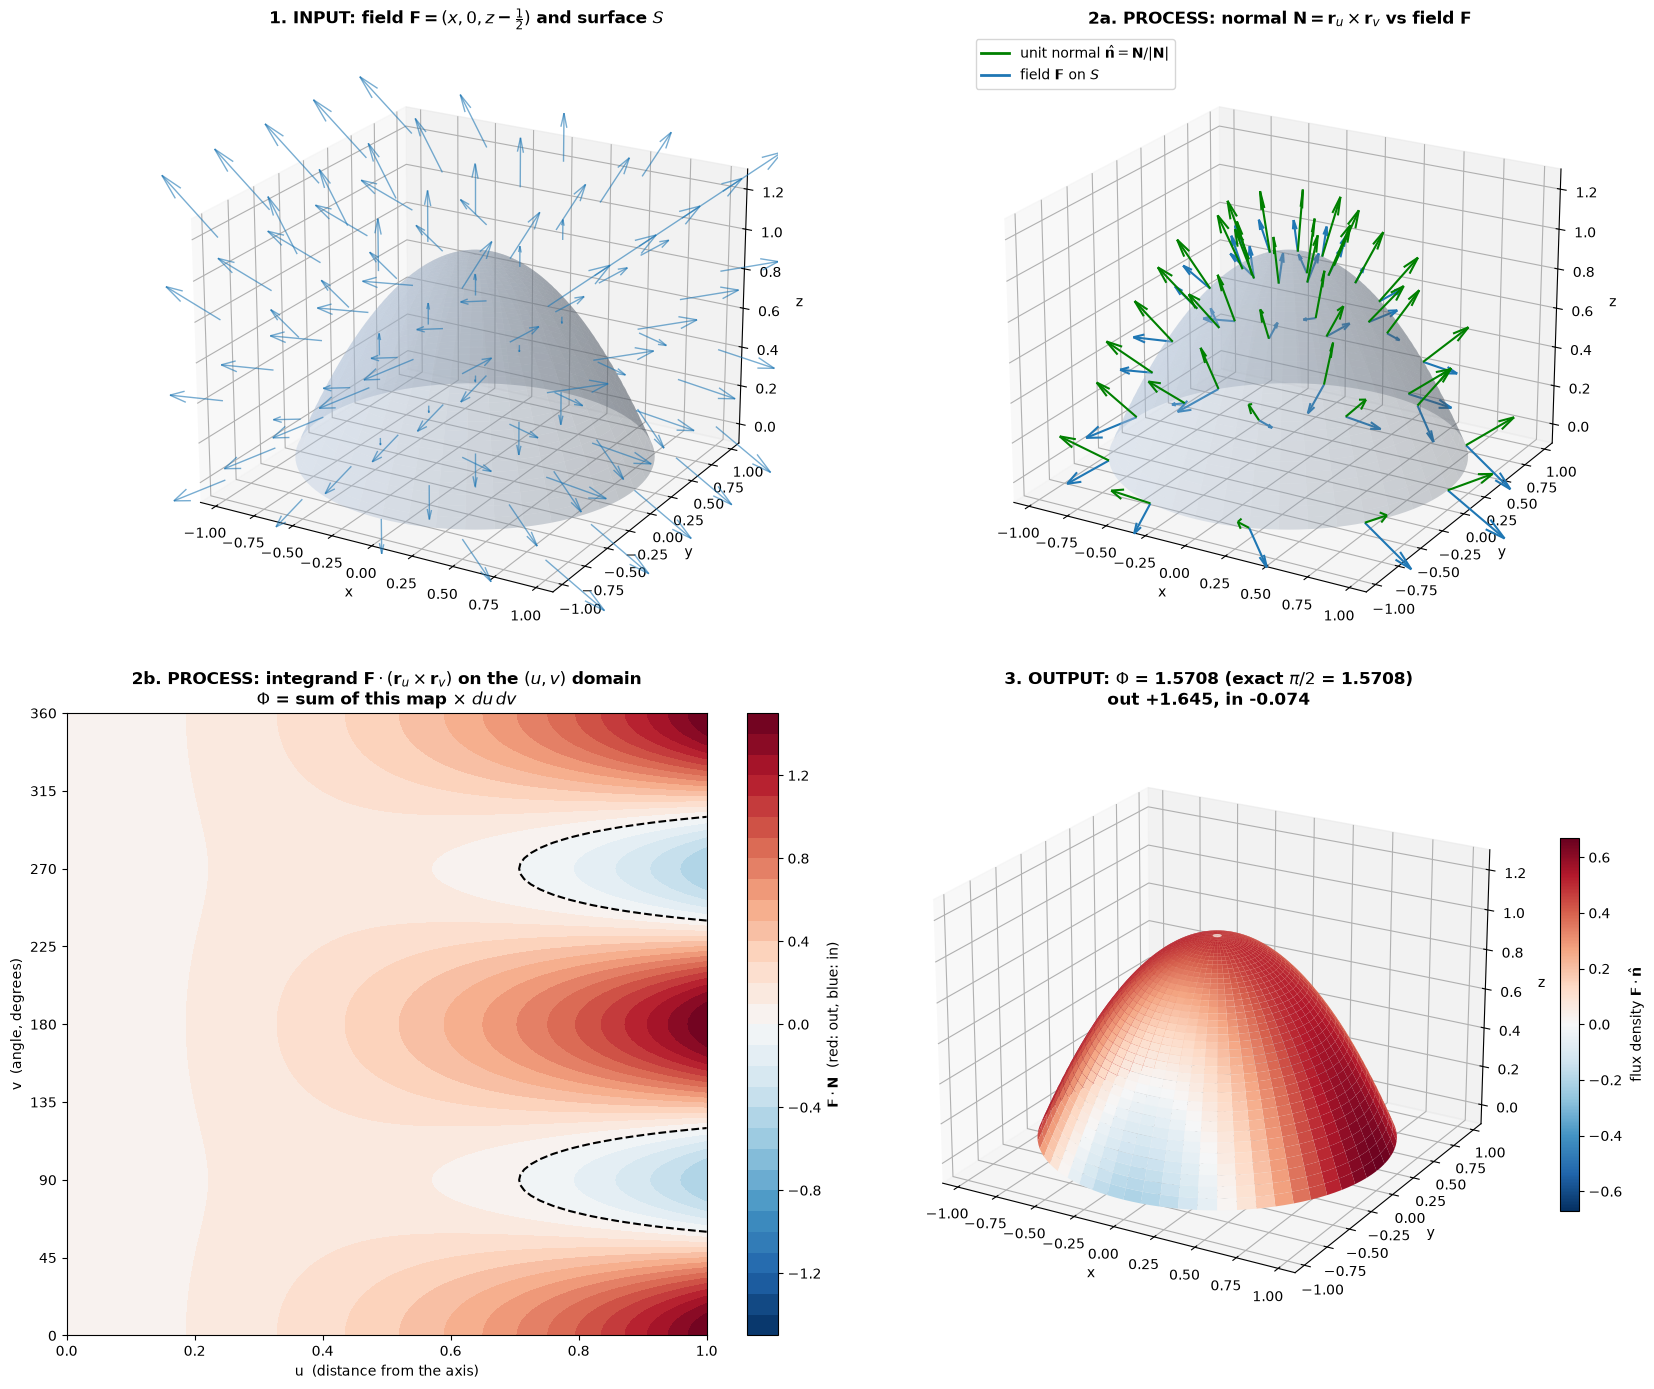

In [2]:
# 2. SURFACE INTEGRAL (FLUX): Phi = iint_S F . n dS = iint_D F(r(u,v)) . (r_u x r_v) du dv
# INPUT: F and surface S  ->  PROCESS: normal N = r_u x r_v, integrand F . N  ->  OUTPUT: flux

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import TwoSlopeNorm

trap = getattr(np, 'trapezoid', None) or getattr(np, 'trapz')

# --- INPUT: paraboloid cap r(u, v) = (u cos v, u sin v, 1 - u^2) and field F = (x, 0, z - 1/2) ---
u = np.linspace(0, 1, 81)
v = np.linspace(0, 2 * np.pi, 121)
U, V = np.meshgrid(u, v)                    # shape (len(v), len(u))
X, Y, Z = U * np.cos(V), U * np.sin(V), 1 - U**2
Fx, Fy, Fz = X, np.zeros_like(X), Z - 0.5

# --- PROCESS: normal vector N = r_u x r_v and the integrand F . N ---
Nx, Ny, Nz = 2 * U**2 * np.cos(V), 2 * U**2 * np.sin(V), U
N_len = np.sqrt(Nx**2 + Ny**2 + Nz**2)
FdotN = Fx * Nx + Fy * Ny + Fz * Nz                    # integrand over (u, v)
Fn = np.divide(FdotN, N_len, out=np.zeros_like(FdotN), where=N_len > 0)   # F . n_hat (flux density)

flux = trap(trap(FdotN, u, axis=1), v)
flux_out = trap(trap(np.clip(FdotN, 0, None), u, axis=1), v)
flux_in = trap(trap(np.clip(FdotN, None, 0), u, axis=1), v)
area = trap(trap(N_len, u, axis=1), v)

print("--- SURFACE INTEGRAL (FLUX) ---")
print(f"surface area of S       = {area:.6f}")
print(f"outward flux (F.n > 0)  = {flux_out:+.6f}")
print(f"inward flux  (F.n < 0)  = {flux_in:+.6f}")
print(f"net flux Phi            = {flux:.6f}   exact pi/2 = {np.pi / 2:.6f}   error {abs(flux - np.pi / 2):.1e}")

# Coarse sample points on the surface for arrows
iu = np.array([20, 40, 60, 80])
iv = np.arange(0, 120, 12)
Pu, Pv = np.meshgrid(iu, iv)
sx, sy, sz = X[Pv, Pu], Y[Pv, Pu], Z[Pv, Pu]
sfx, sfy, sfz = Fx[Pv, Pu], Fy[Pv, Pu], Fz[Pv, Pu]
snx, sny, snz = (Nx / np.where(N_len > 0, N_len, 1))[Pv, Pu], (Ny / np.where(N_len > 0, N_len, 1))[Pv, Pu], \
                (Nz / np.where(N_len > 0, N_len, 1))[Pv, Pu]

fig = plt.figure(figsize=(17, 14))
norm = TwoSlopeNorm(0, -np.abs(Fn).max(), np.abs(Fn).max())


def style3d(ax, title):
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_zlim(-0.1, 1.3)
    ax.view_init(elev=22, azim=-60)
    ax.set_title(title, fontsize=12, fontweight='bold')


# Panel 1: INPUT
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
ax1.plot_surface(X, Y, Z, color='lightsteelblue', alpha=0.35, edgecolor='none')
gx, gy, gz = np.meshgrid(np.linspace(-1, 1, 5), np.linspace(-1, 1, 5), np.linspace(0, 1.2, 4))
ax1.quiver(gx, gy, gz, gx, 0 * gx, gz - 0.5, length=0.35, color='tab:blue', alpha=0.6, linewidth=1)
style3d(ax1, r'1. INPUT: field $\mathbf{F} = (x, 0, z - \frac{1}{2})$ and surface $S$')

# Panel 2a: PROCESS (normals and field on the surface)
ax2 = fig.add_subplot(2, 2, 2, projection='3d')
ax2.plot_surface(X, Y, Z, color='lightsteelblue', alpha=0.3, edgecolor='none')
ax2.quiver(sx, sy, sz, snx, sny, snz, length=0.3, color='green', linewidth=1.5)
ax2.quiver(sx, sy, sz, sfx, sfy, sfz, length=0.35, color='tab:blue', linewidth=1.5)
ax2.plot([], [], color='green', lw=2, label=r'unit normal $\hat{\mathbf{n}} = \mathbf{N}/|\mathbf{N}|$')
ax2.plot([], [], color='tab:blue', lw=2, label=r'field $\mathbf{F}$ on $S$')
ax2.legend(loc='upper left')
style3d(ax2, r'2a. PROCESS: normal $\mathbf{N} = \mathbf{r}_u \times \mathbf{r}_v$ vs field $\mathbf{F}$')

# Panel 2b: PROCESS (integrand on the flat parameter domain)
ax3 = fig.add_subplot(2, 2, 3)
vmax = np.abs(FdotN).max()
cf = ax3.contourf(U, np.degrees(V), FdotN, levels=np.linspace(-vmax, vmax, 31), cmap='RdBu_r')
ax3.contour(U, np.degrees(V), FdotN, levels=[0], colors='k', linewidths=1.5, linestyles='--')
ax3.set_xlabel('u  (distance from the axis)')
ax3.set_ylabel('v  (angle, degrees)')
ax3.set_yticks(range(0, 361, 45))
ax3.set_title(r'2b. PROCESS: integrand $\mathbf{F}\cdot(\mathbf{r}_u\times\mathbf{r}_v)$ on the $(u, v)$ domain'
              + '\n' + r'$\Phi$ = sum of this map $\times\ du\,dv$', fontsize=12, fontweight='bold')
fig.colorbar(cf, ax=ax3, label=r'$\mathbf{F}\cdot\mathbf{N}$  (red: out, blue: in)')

# Panel 3: OUTPUT (flux density on the surface)
ax4 = fig.add_subplot(2, 2, 4, projection='3d')
ax4.plot_surface(X, Y, Z, facecolors=cm.RdBu_r(norm(Fn)), rstride=2, cstride=2, shade=False, edgecolor='none')
sm = cm.ScalarMappable(cmap='RdBu_r', norm=norm)
fig.colorbar(sm, ax=ax4, shrink=0.6, label=r'flux density $\mathbf{F}\cdot\hat{\mathbf{n}}$')
style3d(ax4, rf'3. OUTPUT: $\Phi$ = {flux:.4f} (exact $\pi/2$ = {np.pi / 2:.4f})' + '\n'
        + rf'out {flux_out:+.3f}, in {flux_in:+.3f}')

plt.tight_layout()
plt.show()

## 3. Volume Integrals

$$\iiint_E f\, dV$$

adds up a scalar quantity through a solid region. With a density $\rho$, it gives the **mass** $M = \iiint_E \rho\, dV$ and the **centre of mass** $\bar x = \frac{1}{M}\iiint_E x\,\rho\, dV$ (and the same for $\bar y$, $\bar z$).

Example: the solid $E$ under the paraboloid, $0 \le z \le 1 - x^2 - y^2$, with density $\rho = 1 + \tfrac{x}{2}$ (heavier on the $+x$ side).

In cylindrical coordinates $dV = r\, dz\, dr\, d\theta$. The factor $r$ is the Jacobian: rings further from the axis hold more volume.

Exact results: $M = \tfrac{\pi}{2}$, $\bar x = \tfrac{1}{12}$, $\bar y = 0$, $\bar z = \tfrac{1}{3}$.

--- VOLUME INTEGRAL ---
volume       = 1.570639   exact pi/2 = 1.570796
mass M       = 1.570639   exact pi/2 = 1.570796   error 1.6e-04
centre of mass = (0.08332, -0.00000, 0.33335)   exact (1/12, 0, 1/3) = (0.08333, 0, 0.33333)


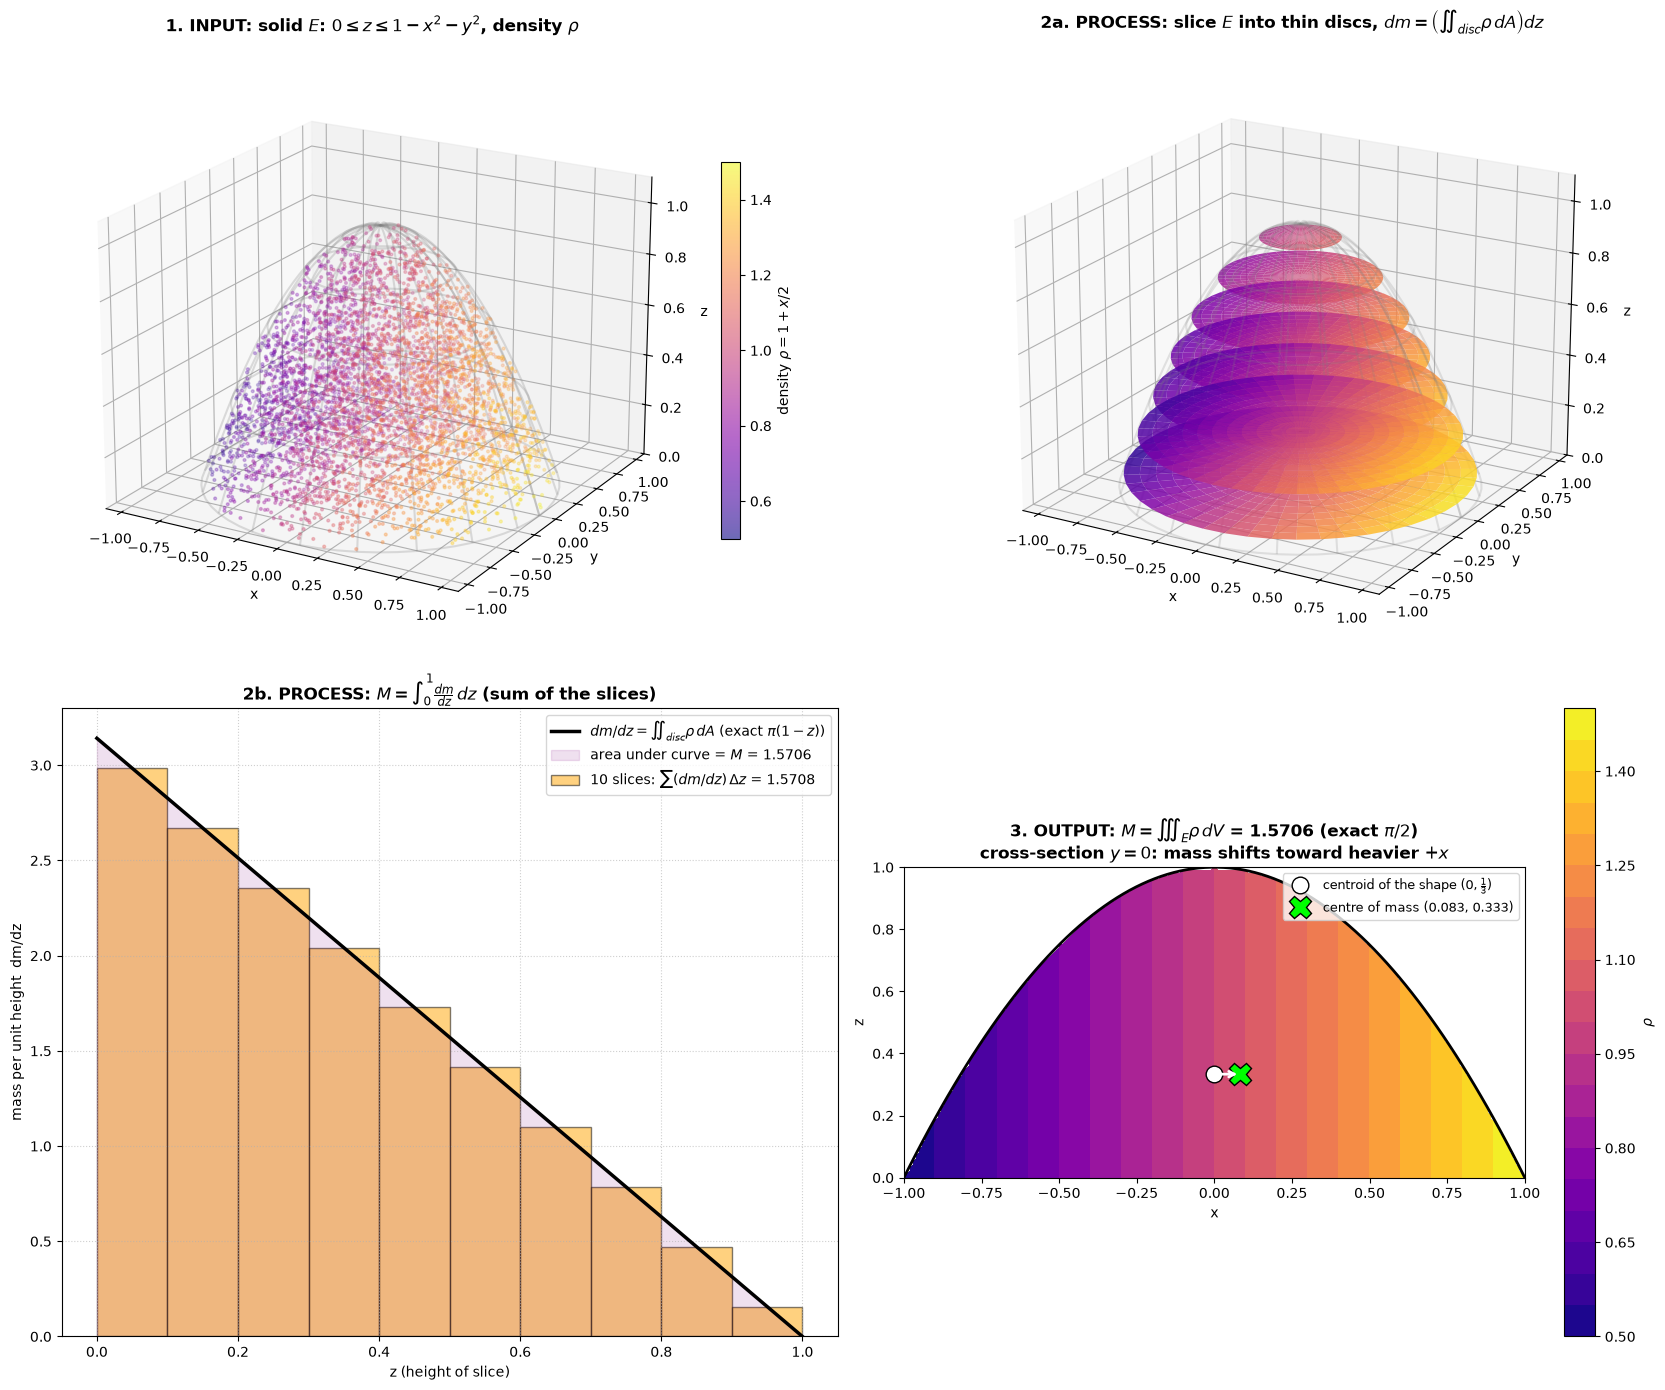

In [3]:
# 3. VOLUME INTEGRAL: mass M = iiint_E rho dV and centre of mass
# INPUT: solid E and density rho  ->  PROCESS: slice into thin discs, sum rho dV  ->  OUTPUT: mass, centre of mass

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize

trap = getattr(np, 'trapezoid', None) or getattr(np, 'trapz')


def rho(x, y, z):
    return 1 + 0.5 * x


# --- PROCESS: triple integral in cylindrical coordinates, dV = r dz dr dtheta ---
# z runs from 0 to 1 - r^2; substitute z = s (1 - r^2) with s in [0, 1], so dz = (1 - r^2) ds
r = np.linspace(0, 1, 101)
th = np.linspace(0, 2 * np.pi, 121)
s = np.linspace(0, 1, 51)
R, TH, S = np.meshgrid(r, th, s, indexing='ij')
Xc, Yc, Zc = R * np.cos(TH), R * np.sin(TH), S * (1 - R**2)
jac = R * (1 - R**2)                       # r (Jacobian) x (1 - r^2) (from dz = (1 - r^2) ds)


def integrate(fv):
    return trap(trap(trap(fv * jac, s, axis=2), th, axis=1), r)


dens = rho(Xc, Yc, Zc)
volume = integrate(np.ones_like(dens))
M = integrate(dens)
x_bar, y_bar, z_bar = integrate(Xc * dens) / M, integrate(Yc * dens) / M, integrate(Zc * dens) / M

print("--- VOLUME INTEGRAL ---")
print(f"volume       = {volume:.6f}   exact pi/2 = {np.pi / 2:.6f}")
print(f"mass M       = {M:.6f}   exact pi/2 = {np.pi / 2:.6f}   error {abs(M - np.pi / 2):.1e}")
print(f"centre of mass = ({x_bar:.5f}, {y_bar:.5f}, {z_bar:.5f})   exact (1/12, 0, 1/3) = ({1/12:.5f}, 0, {1/3:.5f})")

# Mass per unit height dm/dz: integrate rho over the disc at height z (radius sqrt(1 - z))
z_line = np.linspace(0, 1, 201)
dm_dz = []
for zz in z_line:
    rr = np.linspace(0, np.sqrt(1 - zz), 60)
    RR, TT = np.meshgrid(rr, th, indexing='ij')
    dm_dz.append(trap(trap(rho(RR * np.cos(TT), RR * np.sin(TT), zz) * RR, th, axis=1), rr))
dm_dz = np.array(dm_dz)

fig = plt.figure(figsize=(17, 14))
dnorm = Normalize(0.5, 1.5)


def style3d(ax, title):
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_zlim(0, 1.1)
    ax.view_init(elev=20, azim=-60)
    ax.set_title(title, fontsize=12, fontweight='bold')


uu, vv = np.meshgrid(np.linspace(0, 1, 30), np.linspace(0, 2 * np.pi, 60))
cap = (uu * np.cos(vv), uu * np.sin(vv), 1 - uu**2)

# Panel 1: INPUT (random points inside E, coloured by density)
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
rng = np.random.default_rng(0)
pts = rng.uniform([-1, -1, 0], [1, 1, 1], size=(12000, 3))
pts = pts[pts[:, 2] <= 1 - pts[:, 0]**2 - pts[:, 1]**2]
sc = ax1.scatter(pts[:, 0], pts[:, 1], pts[:, 2], c=rho(*pts.T), cmap='plasma', norm=dnorm, s=4, alpha=0.6)
ax1.plot_wireframe(*cap, color='gray', alpha=0.25, rstride=3, cstride=6)
fig.colorbar(sc, ax=ax1, shrink=0.6, label=r'density $\rho = 1 + x/2$')
style3d(ax1, r'1. INPUT: solid $E$: $0 \leq z \leq 1 - x^2 - y^2$, density $\rho$')

# Panel 2a: PROCESS (thin disc slices)
ax2 = fig.add_subplot(2, 2, 2, projection='3d')
ax2.plot_wireframe(*cap, color='gray', alpha=0.2, rstride=3, cstride=6)
for zz in np.linspace(0.05, 0.95, 7):
    rd, td = np.meshgrid(np.linspace(0, np.sqrt(1 - zz), 12), np.linspace(0, 2 * np.pi, 48))
    dx, dy = rd * np.cos(td), rd * np.sin(td)
    ax2.plot_surface(dx, dy, np.full_like(dx, zz), facecolors=cm.plasma(dnorm(rho(dx, dy, zz))),
                     shade=False, alpha=0.85, edgecolor='none')
style3d(ax2, r'2a. PROCESS: slice $E$ into thin discs, $dm = \left(\iint_{disc} \rho\, dA\right) dz$')

# Panel 2b: PROCESS (mass per slice and its Riemann sum)
ax3 = fig.add_subplot(2, 2, 3)
n_slices = 10
edges = np.linspace(0, 1, n_slices + 1)
mids = 0.5 * (edges[1:] + edges[:-1])
bar_h = np.interp(mids, z_line, dm_dz)
ax3.bar(mids, bar_h, width=1 / n_slices, color='orange', alpha=0.5, edgecolor='k',
        label=rf'{n_slices} slices: $\sum (dm/dz)\,\Delta z$ = {np.sum(bar_h) / n_slices:.4f}')
ax3.plot(z_line, dm_dz, 'k-', lw=2.5, label=r'$dm/dz = \iint_{disc} \rho\, dA$ (exact $\pi(1 - z)$)')
ax3.fill_between(z_line, dm_dz, color='purple', alpha=0.12, label=rf'area under curve = $M$ = {M:.4f}')
ax3.set_xlabel('z (height of slice)')
ax3.set_ylabel('mass per unit height  dm/dz')
ax3.legend(loc='upper right')
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.set_title(r'2b. PROCESS: $M = \int_0^1 \frac{dm}{dz}\, dz$ (sum of the slices)', fontsize=12, fontweight='bold')

# Panel 3: OUTPUT (cross-section y = 0 with centre of mass)
ax4 = fig.add_subplot(2, 2, 4)
xs, zs = np.meshgrid(np.linspace(-1, 1, 201), np.linspace(0, 1, 101))
inside = zs <= 1 - xs**2
cf = ax4.contourf(xs, zs, np.where(inside, rho(xs, 0, zs), np.nan), levels=20, cmap='plasma', norm=dnorm)
ax4.plot(np.linspace(-1, 1, 100), 1 - np.linspace(-1, 1, 100)**2, 'k-', lw=2)
ax4.plot(0, 1 / 3, 'wo', ms=12, mec='k', label=r'centroid of the shape $(0, \frac{1}{3})$')
ax4.plot(x_bar, z_bar, 'X', color='lime', ms=16, mec='k', label=rf'centre of mass ({x_bar:.3f}, {z_bar:.3f})')
ax4.annotate('', xy=(x_bar, z_bar), xytext=(0, 1 / 3), arrowprops=dict(arrowstyle='->', lw=2, color='w'))
ax4.set_xlabel('x')
ax4.set_ylabel('z')
ax4.set_aspect('equal')
ax4.legend(loc='upper right', fontsize=9)
fig.colorbar(cf, ax=ax4, label=r'$\rho$')
ax4.set_title(rf'3. OUTPUT: $M = \iiint_E \rho\, dV$ = {M:.4f} (exact $\pi/2$)' + '\n'
              + r'cross-section $y = 0$: mass shifts toward heavier $+x$', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 4. Path Independence and Potentials

A field is **conservative** if it is the gradient of a potential, $\mathbf F = \nabla\varphi$. Then the Fundamental Theorem of Line Integrals gives

$$\int_C \nabla\varphi\cdot d\mathbf r = \varphi(B) - \varphi(A)$$

for **every** path from $A$ to $B$. Equivalent statements (on a simply connected region):

| $\mathbf F = \nabla\varphi$ | $\iff$ | work is path independent | $\iff$ | $\oint_C \mathbf F\cdot d\mathbf r = 0$ for every loop | $\iff$ | $\nabla\times\mathbf F = 0$ |
|---|---|---|---|---|---|---|

The first cell compares a conservative field $\mathbf F = \nabla\varphi$ (the hill-and-valley potential from the differential notebook) with the non-conservative $\mathbf G = (-y, x)$ along three different paths. The second cell recovers $\varphi$ from $\mathbf F$ alone by integrating along L-shaped paths:

$$\varphi(x, y) = \int_0^x P(s, 0)\, ds + \int_0^y Q(x, t)\, dt, \qquad \mathbf F = (P, Q)$$

--- PATH INDEPENDENCE ---
phi(B) - phi(A) = 0.703902
  straight: work of F = 0.703902   work of G = 0.120000
  arc     : work of F = 0.703901   work of G = -5.225422
  wiggle  : work of F = 0.703902   work of G = 0.862418
closed loop (arc - straight): F -> -5.5e-07   G -> -5.345422  (= -2 x enclosed area = -5.345423, clockwise loop)


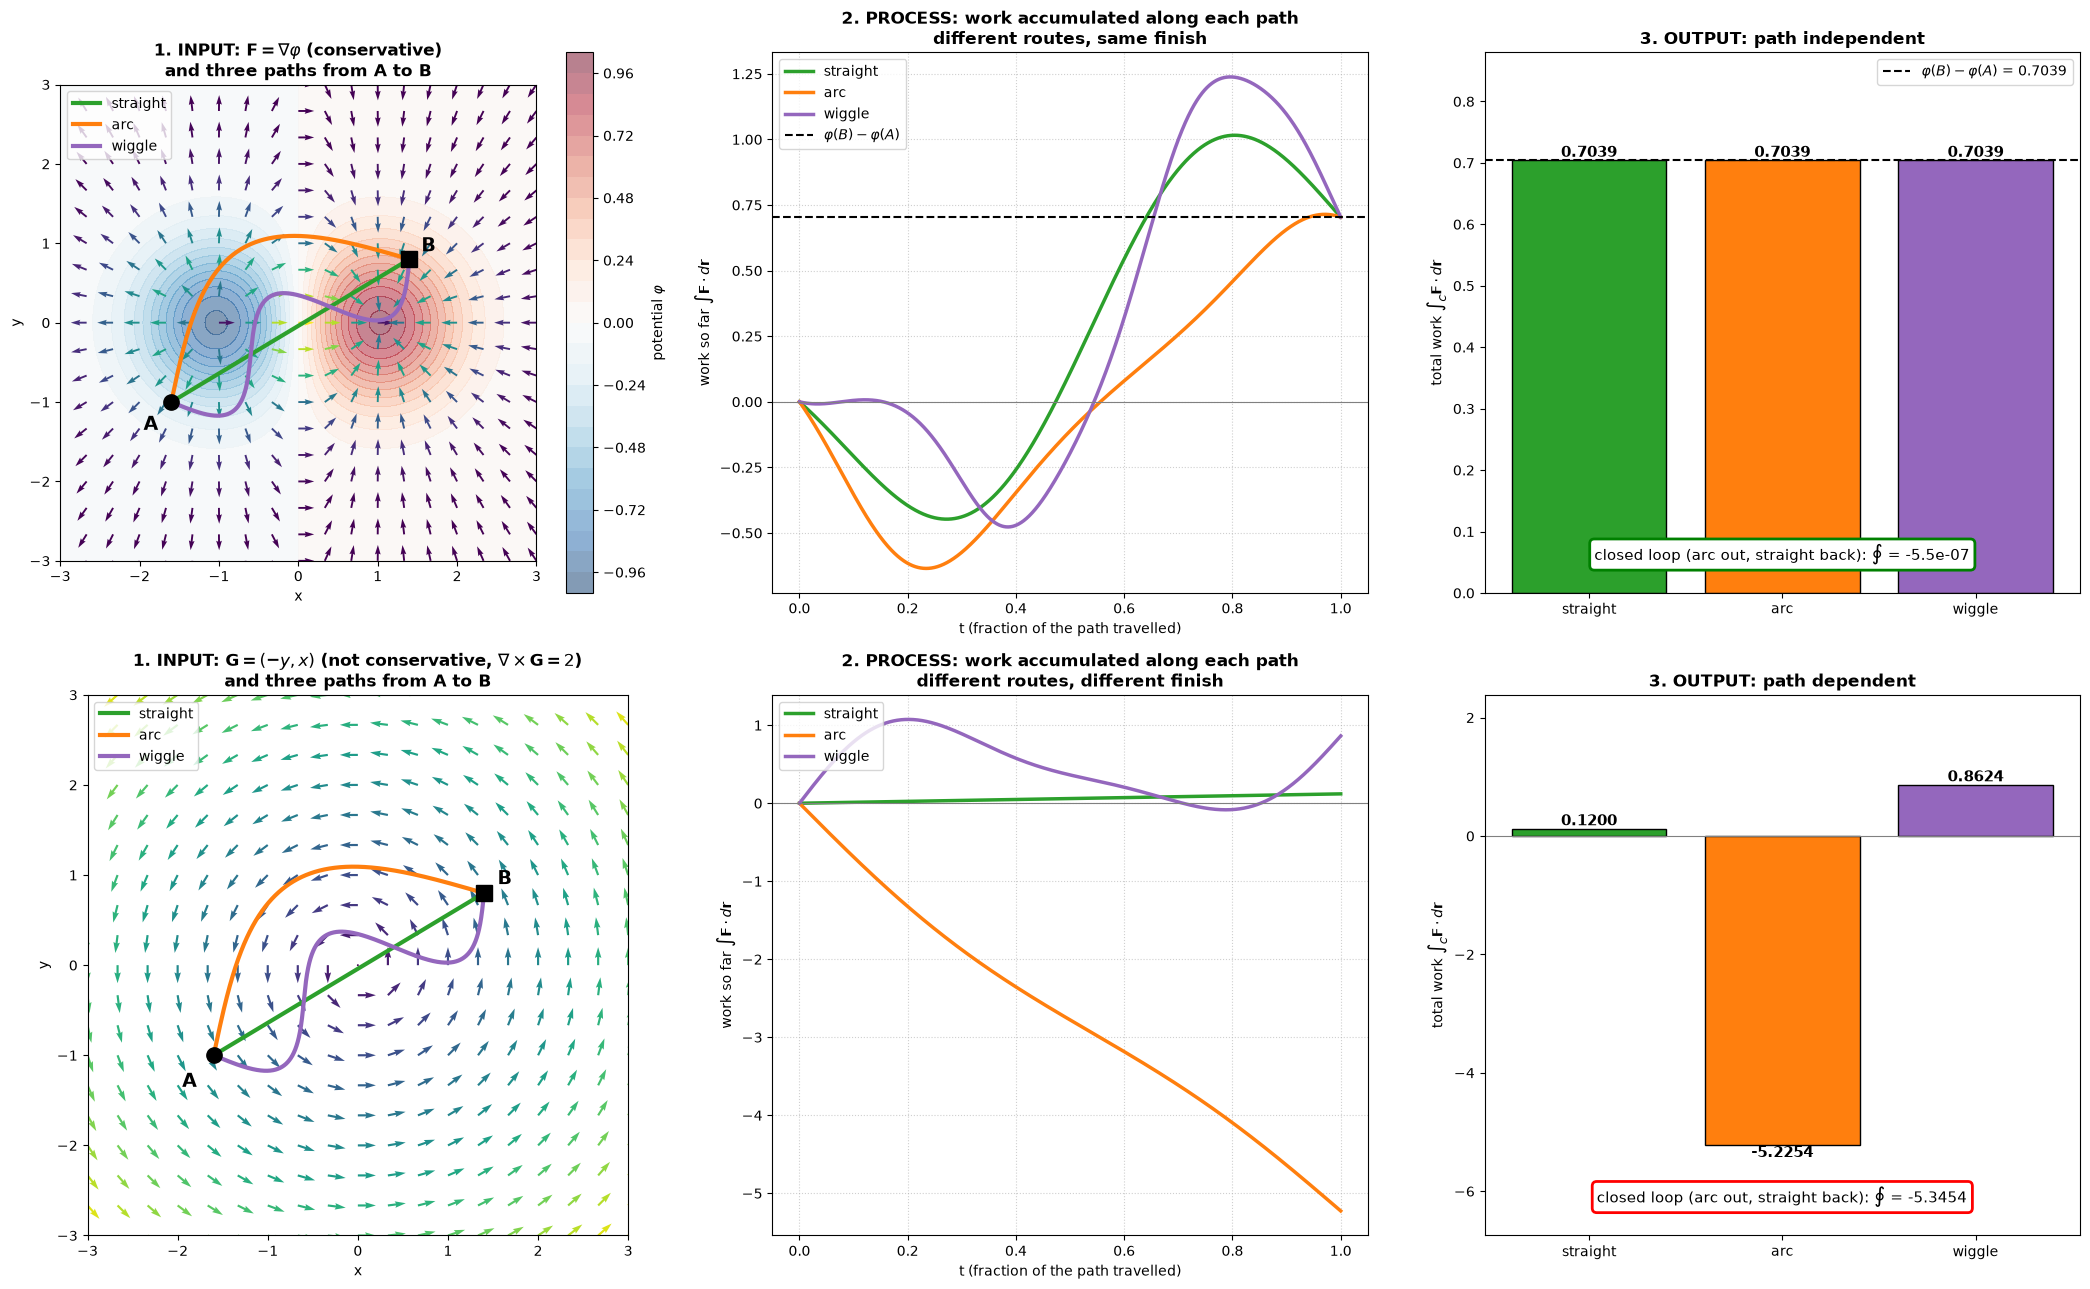

In [4]:
# 4a. PATH INDEPENDENCE: same work on every path for F = grad(phi), not for G = (-y, x)
# INPUT: field + three paths A -> B  ->  PROCESS: accumulate F . dr along each  ->  OUTPUT: compare totals

import numpy as np
import matplotlib.pyplot as plt


def phi(x, y):
    return np.exp(-((x - 1)**2 + y**2)) - np.exp(-((x + 1)**2 + y**2))


def F(x, y):                       # F = grad(phi), conservative
    hill = np.exp(-((x - 1)**2 + y**2))
    valley = np.exp(-((x + 1)**2 + y**2))
    return -2 * (x - 1) * hill + 2 * (x + 1) * valley, -2 * y * hill + 2 * y * valley


def G(x, y):                       # rotation, curl G = 2, not conservative
    return -y, x


def cumtrap(fv, t):
    return np.concatenate([[0.0], np.cumsum(0.5 * (fv[1:] + fv[:-1]) * np.diff(t))])


# --- INPUT: three paths from A to B ---
A, B = np.array([-1.6, -1.0]), np.array([1.4, 0.8])
t = np.linspace(0, 1, 2001)
d = B - A
n_hat = np.array([-d[1], d[0]]) / np.linalg.norm(d)
base = A + np.outer(t, d)
paths = {
    'straight': base,
    'arc': base + np.outer(1.2 * np.sin(np.pi * t), n_hat),
    'wiggle': base + np.outer(-0.5 * np.sin(3 * np.pi * t), n_hat),
}
colors = {'straight': 'tab:green', 'arc': 'tab:orange', 'wiggle': 'tab:purple'}

# --- PROCESS: accumulate the work along each path ---
work = {}
for field_name, field in [('F', F), ('G', G)]:
    for name, p in paths.items():
        dp = np.gradient(p, t, axis=0)
        fx, fy = field(p[:, 0], p[:, 1])
        work[field_name, name] = cumtrap(fx * dp[:, 0] + fy * dp[:, 1], t)

dphi = phi(*B) - phi(*A)
loop_F = work['F', 'arc'][-1] - work['F', 'straight'][-1]      # arc out, straight back
loop_G = work['G', 'arc'][-1] - work['G', 'straight'][-1]
area_between = 1.2 * np.linalg.norm(d) * 2 / np.pi             # area between arc and straight line

print("--- PATH INDEPENDENCE ---")
print(f"phi(B) - phi(A) = {dphi:.6f}")
for name in paths:
    print(f"  {name:8s}: work of F = {work['F', name][-1]:.6f}   work of G = {work['G', name][-1]:.6f}")
print(f"closed loop (arc - straight): F -> {loop_F:.1e}   G -> {loop_G:.6f}  "
      f"(= -2 x enclosed area = {-2 * area_between:.6f}, clockwise loop)")

# --- Visualization ---
g = np.linspace(-3, 3, 19)
GX, GY = np.meshgrid(g, g)
fine = np.linspace(-3, 3, 121)
FX, FY = np.meshgrid(fine, fine)

fig, axes = plt.subplots(2, 3, figsize=(21, 13))
rows = [
    ('F', F, r'$\mathbf{F} = \nabla\varphi$ (conservative)', True),
    ('G', G, r'$\mathbf{G} = (-y, x)$ (not conservative, $\nabla\times\mathbf{G} = 2$)', False),
]
for r, (key, field, label, conservative) in enumerate(rows):
    # INPUT
    ax = axes[r, 0]
    if conservative:
        cf = ax.contourf(FX, FY, phi(FX, FY), levels=30, cmap='RdBu_r', alpha=0.5)
        fig.colorbar(cf, ax=ax, label=r'potential $\varphi$')
    U, V = field(GX, GY)
    M = np.hypot(U, V)
    ax.quiver(GX, GY, U / np.where(M > 0, M, 1), V / np.where(M > 0, M, 1), M, cmap='viridis', scale=30, width=0.004)
    for name, p in paths.items():
        ax.plot(p[:, 0], p[:, 1], color=colors[name], lw=3, label=name)
    ax.plot(*A, 'o', color='k', ms=11)
    ax.plot(*B, 's', color='k', ms=11)
    ax.text(A[0] - 0.35, A[1] - 0.35, 'A', fontsize=14, fontweight='bold')
    ax.text(B[0] + 0.15, B[1] + 0.1, 'B', fontsize=14, fontweight='bold')
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_aspect('equal')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.legend(loc='upper left')
    ax.set_title('1. INPUT: ' + label + '\nand three paths from A to B', fontsize=12, fontweight='bold')

    # PROCESS
    ax = axes[r, 1]
    for name in paths:
        ax.plot(t, work[key, name], color=colors[name], lw=2.5, label=name)
    if conservative:
        ax.axhline(dphi, color='k', ls='--', lw=1.5, label=r'$\varphi(B) - \varphi(A)$')
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_xlabel('t (fraction of the path travelled)')
    ax.set_ylabel(r'work so far $\int \mathbf{F}\cdot d\mathbf{r}$')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper left')
    ax.set_title('2. PROCESS: work accumulated along each path\n'
                 + ('different routes, same finish' if conservative else 'different routes, different finish'),
                 fontsize=12, fontweight='bold')

    # OUTPUT
    ax = axes[r, 2]
    names = list(paths)
    vals = [work[key, n][-1] for n in names]
    bars = ax.bar(names, vals, color=[colors[n] for n in names], edgecolor='k')
    if conservative:
        ax.axhline(dphi, color='k', ls='--', lw=1.5, label=rf'$\varphi(B) - \varphi(A)$ = {dphi:.4f}')
        ax.legend(loc='upper right')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, val, f'{val:.4f}', ha='center',
                va='bottom' if val >= 0 else 'top', fontsize=11, fontweight='bold')
    ax.axhline(0, color='gray', lw=0.8)
    loop = loop_F if conservative else loop_G
    ax.text(0.5, 0.06, rf'closed loop (arc out, straight back): $\oint$ = {loop:.1e}' if conservative
            else rf'closed loop (arc out, straight back): $\oint$ = {loop:.4f}',
            transform=ax.transAxes, ha='center', fontsize=11,
            bbox=dict(boxstyle='round', fc='w', ec='green' if conservative else 'red', lw=2))
    ax.set_ylabel(r'total work $\int_C \mathbf{F}\cdot d\mathbf{r}$')
    ax.margins(y=0.25)
    ax.set_title('3. OUTPUT: ' + ('path independent' if conservative else 'path dependent'),
                 fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

--- FINDING THE POTENTIAL ---
max |curl F|                 = 5.87e-03  (vs |dQ/dx| up to 1.26) -> conservative
max |phi recovered - phi|    = 4.75e-04
max |grad(phi recovered) - F| = 6.88e-03


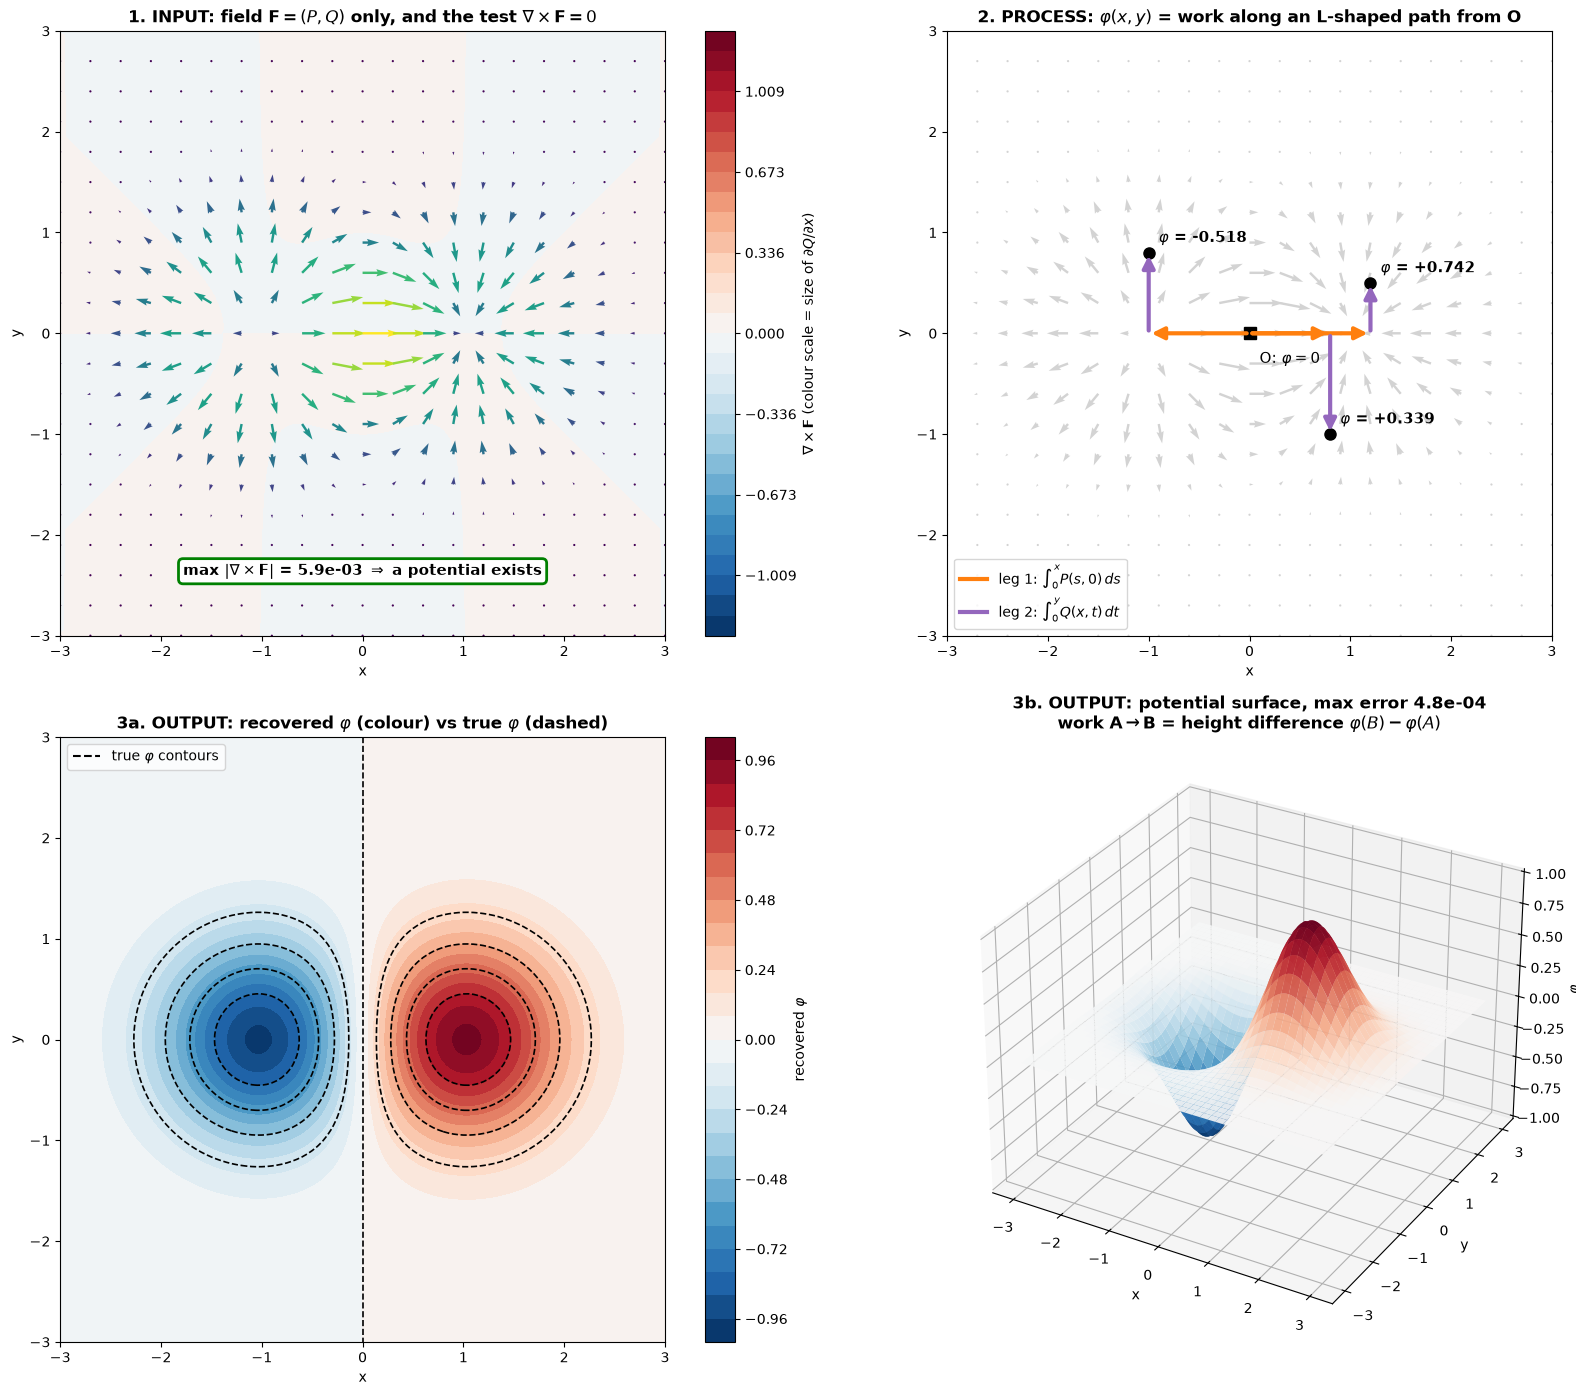

In [5]:
# 4b. FINDING THE POTENTIAL: recover phi from F alone
# INPUT: F (check curl F = 0)  ->  PROCESS: integrate along L-shaped paths from the origin  ->  OUTPUT: phi

import numpy as np
import matplotlib.pyplot as plt


def phi_true(x, y):
    return np.exp(-((x - 1)**2 + y**2)) - np.exp(-((x + 1)**2 + y**2))


def F(x, y):
    hill = np.exp(-((x - 1)**2 + y**2))
    valley = np.exp(-((x + 1)**2 + y**2))
    return -2 * (x - 1) * hill + 2 * (x + 1) * valley, -2 * y * hill + 2 * y * valley


def cumtrap_axis(fv, t, axis):
    # Cumulative trapezoid integral along an axis, starting at 0
    fv = np.moveaxis(fv, axis, 0)
    steps = 0.5 * (fv[1:] + fv[:-1]) * np.diff(t).reshape(-1, *[1] * (fv.ndim - 1))
    out = np.concatenate([np.zeros_like(fv[:1]), np.cumsum(steps, axis=0)])
    return np.moveaxis(out, 0, axis)


# --- INPUT: only the field F = (P, Q) is known ---
x = np.linspace(-3, 3, 121)
y = np.linspace(-3, 3, 121)
X, Y = np.meshgrid(x, y)
P, Q = F(X, Y)

# Test for a potential: curl F = dQ/dx - dP/dy must vanish
dQ_dx = np.gradient(Q, x, axis=1)
dP_dy = np.gradient(P, y, axis=0)
curl = dQ_dx - dP_dy

# --- PROCESS: phi(x, y) = int_0^x P(s, 0) ds + int_0^y Q(x, t) dt ---
i0, j0 = np.argmin(np.abs(y)), np.argmin(np.abs(x))
leg1 = cumtrap_axis(P[i0, :], x, axis=0)
leg1 -= leg1[j0]                                  # int_0^x P(s, 0) ds
leg2 = cumtrap_axis(Q, y, axis=0)
leg2 -= leg2[i0, :]                               # int_0^y Q(x, t) dt, for every x
phi_rec = leg1[None, :] + leg2
phi_ref = phi_true(X, Y) - phi_true(0, 0)

print("--- FINDING THE POTENTIAL ---")
print(f"max |curl F|                 = {np.max(np.abs(curl)):.2e}  (vs |dQ/dx| up to {np.abs(dQ_dx).max():.2f}) -> conservative")
print(f"max |phi recovered - phi|    = {np.max(np.abs(phi_rec - phi_ref)):.2e}")
print(f"max |grad(phi recovered) - F| = "
      f"{max(np.abs(np.gradient(phi_rec, x, axis=1) - P).max(), np.abs(np.gradient(phi_rec, y, axis=0) - Q).max()):.2e}")

# --- Visualization ---
fig = plt.figure(figsize=(17, 14))
s = 6
mag = np.hypot(P, Q)

# Panel 1: INPUT (field and curl test)
ax1 = fig.add_subplot(2, 2, 1)
ref = np.abs(dQ_dx).max()
cf = ax1.contourf(X, Y, curl, levels=np.linspace(-ref, ref, 31), cmap='RdBu_r')
ax1.quiver(X[::s, ::s], Y[::s, ::s], P[::s, ::s], Q[::s, ::s], mag[::s, ::s], cmap='viridis',
           scale_units='xy', scale=4, width=0.004)
ax1.text(0, -2.4, rf'max $|\nabla\times\mathbf{{F}}|$ = {np.max(np.abs(curl)):.1e} $\Rightarrow$ a potential exists',
         ha='center', fontsize=11, fontweight='bold', bbox=dict(boxstyle='round', fc='w', ec='green', lw=2))
fig.colorbar(cf, ax=ax1, label=r'$\nabla\times\mathbf{F}$ (colour scale = size of $\partial Q/\partial x$)')
ax1.set_title(r'1. INPUT: field $\mathbf{F} = (P, Q)$ only, and the test $\nabla\times\mathbf{F} = 0$',
              fontsize=12, fontweight='bold')

# Panel 2: PROCESS (L-shaped integration paths)
ax2 = fig.add_subplot(2, 2, 2)
ax2.quiver(X[::s, ::s], Y[::s, ::s], P[::s, ::s], Q[::s, ::s], color='lightgray',
           scale_units='xy', scale=4, width=0.004)
for k, (px, py) in enumerate([(1.2, 0.5), (-1.0, 0.8), (0.8, -1.0)]):
    ax2.annotate('', xy=(px, 0), xytext=(0, 0),
                 arrowprops=dict(arrowstyle='-|>', color='tab:orange', lw=3, mutation_scale=18))
    ax2.annotate('', xy=(px, py), xytext=(px, 0),
                 arrowprops=dict(arrowstyle='-|>', color='tab:purple', lw=3, mutation_scale=18))
    jx, iy = np.argmin(np.abs(x - px)), np.argmin(np.abs(y - py))
    ax2.plot(px, py, 'ko', ms=8)
    ax2.text(px + 0.1, py + 0.1, rf'$\varphi$ = {phi_rec[iy, jx]:+.3f}', fontsize=11, fontweight='bold')
ax2.plot(0, 0, 'ks', ms=9)
ax2.text(0.1, -0.3, r'O: $\varphi = 0$', fontsize=11)
ax2.plot([], [], color='tab:orange', lw=3, label=r'leg 1: $\int_0^x P(s, 0)\, ds$')
ax2.plot([], [], color='tab:purple', lw=3, label=r'leg 2: $\int_0^y Q(x, t)\, dt$')
ax2.legend(loc='lower left')
ax2.set_title(r'2. PROCESS: $\varphi(x, y)$ = work along an L-shaped path from O', fontsize=12, fontweight='bold')

# Panel 3a: OUTPUT (recovered vs true potential)
ax3 = fig.add_subplot(2, 2, 3)
cf3 = ax3.contourf(X, Y, phi_rec, levels=30, cmap='RdBu_r')
ax3.contour(X, Y, phi_ref, levels=12, colors='k', linewidths=1.2, linestyles='--')
ax3.plot([], [], 'k--', label=r'true $\varphi$ contours')
ax3.legend(loc='upper left')
fig.colorbar(cf3, ax=ax3, label=r'recovered $\varphi$')
ax3.set_title(r'3a. OUTPUT: recovered $\varphi$ (colour) vs true $\varphi$ (dashed)', fontsize=12, fontweight='bold')

for ax in (ax1, ax2, ax3):
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_aspect('equal')
    ax.set_xlabel('x')
    ax.set_ylabel('y')

# Panel 3b: OUTPUT (surface)
ax4 = fig.add_subplot(2, 2, 4, projection='3d')
ax4.plot_surface(X, Y, phi_rec, cmap='RdBu_r', edgecolor='none', alpha=0.9)
ax4.set_xlabel('x')
ax4.set_ylabel('y')
ax4.set_zlabel(r'$\varphi$')
ax4.view_init(elev=30, azim=-60)
ax4.set_title(rf'3b. OUTPUT: potential surface, max error {np.max(np.abs(phi_rec - phi_ref)):.1e}' + '\n'
              + r'work A$\to$B = height difference $\varphi(B) - \varphi(A)$', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 5. The Integral Theorems

Each theorem says that integrating a **derivative** over a region equals integrating the **field** over the region's boundary:

| Theorem | Statement | Derivative from the differential notebook |
|---|---|---|
| Fundamental Theorem of Line Integrals | $\int_C \nabla\varphi\cdot d\mathbf r = \varphi(B) - \varphi(A)$ | gradient (section 4) |
| Green | $\oint_C \mathbf F\cdot d\mathbf r = \iint_D \left(\partial_x Q - \partial_y P\right) dA$ | 2D curl (section 1, circulation $= 2\times$ area) |
| Stokes | $\oint_{\partial S} \mathbf F\cdot d\mathbf r = \iint_S (\nabla\times\mathbf F)\cdot\hat{\mathbf n}\, dS$ | curl |
| Divergence (Gauss) | $\iint_{\partial E} \mathbf F\cdot\hat{\mathbf n}\, dS = \iiint_E \nabla\cdot\mathbf F\, dV$ | divergence |

Both checks below reuse the paraboloid from sections 2 and 3:
- **Divergence theorem**: $\mathbf F = (x, 0, z - \tfrac12)$ has $\nabla\cdot\mathbf F = 2$. The closed surface $\partial E$ is the cap (flux $\pi/2$, section 2) plus the flat base disc. The volume side is $2 \times \text{volume} = \pi$.
- **Stokes' theorem**: $\mathbf H = (z - y,\ x,\ xy)$ has $\nabla\times\mathbf H = (x,\ 1 - y,\ 2)$. The cap $S$ has boundary $C$: the unit circle at $z = 0$, counter-clockwise seen from above. Both sides equal $2\pi$.

--- DIVERGENCE THEOREM ---
flux through cap  = 1.570796   (exact pi/2)
flux through base = 1.570796   (exact pi/2)
closed-surface flux = 3.141593
iiint div F dV      = 3.141514   (exact pi = 3.141593)
--- STOKES' THEOREM ---
circulation around C  = 6.283185
iint (curl H) . n dS  = 6.283185   (exact 2 pi = 6.283185)


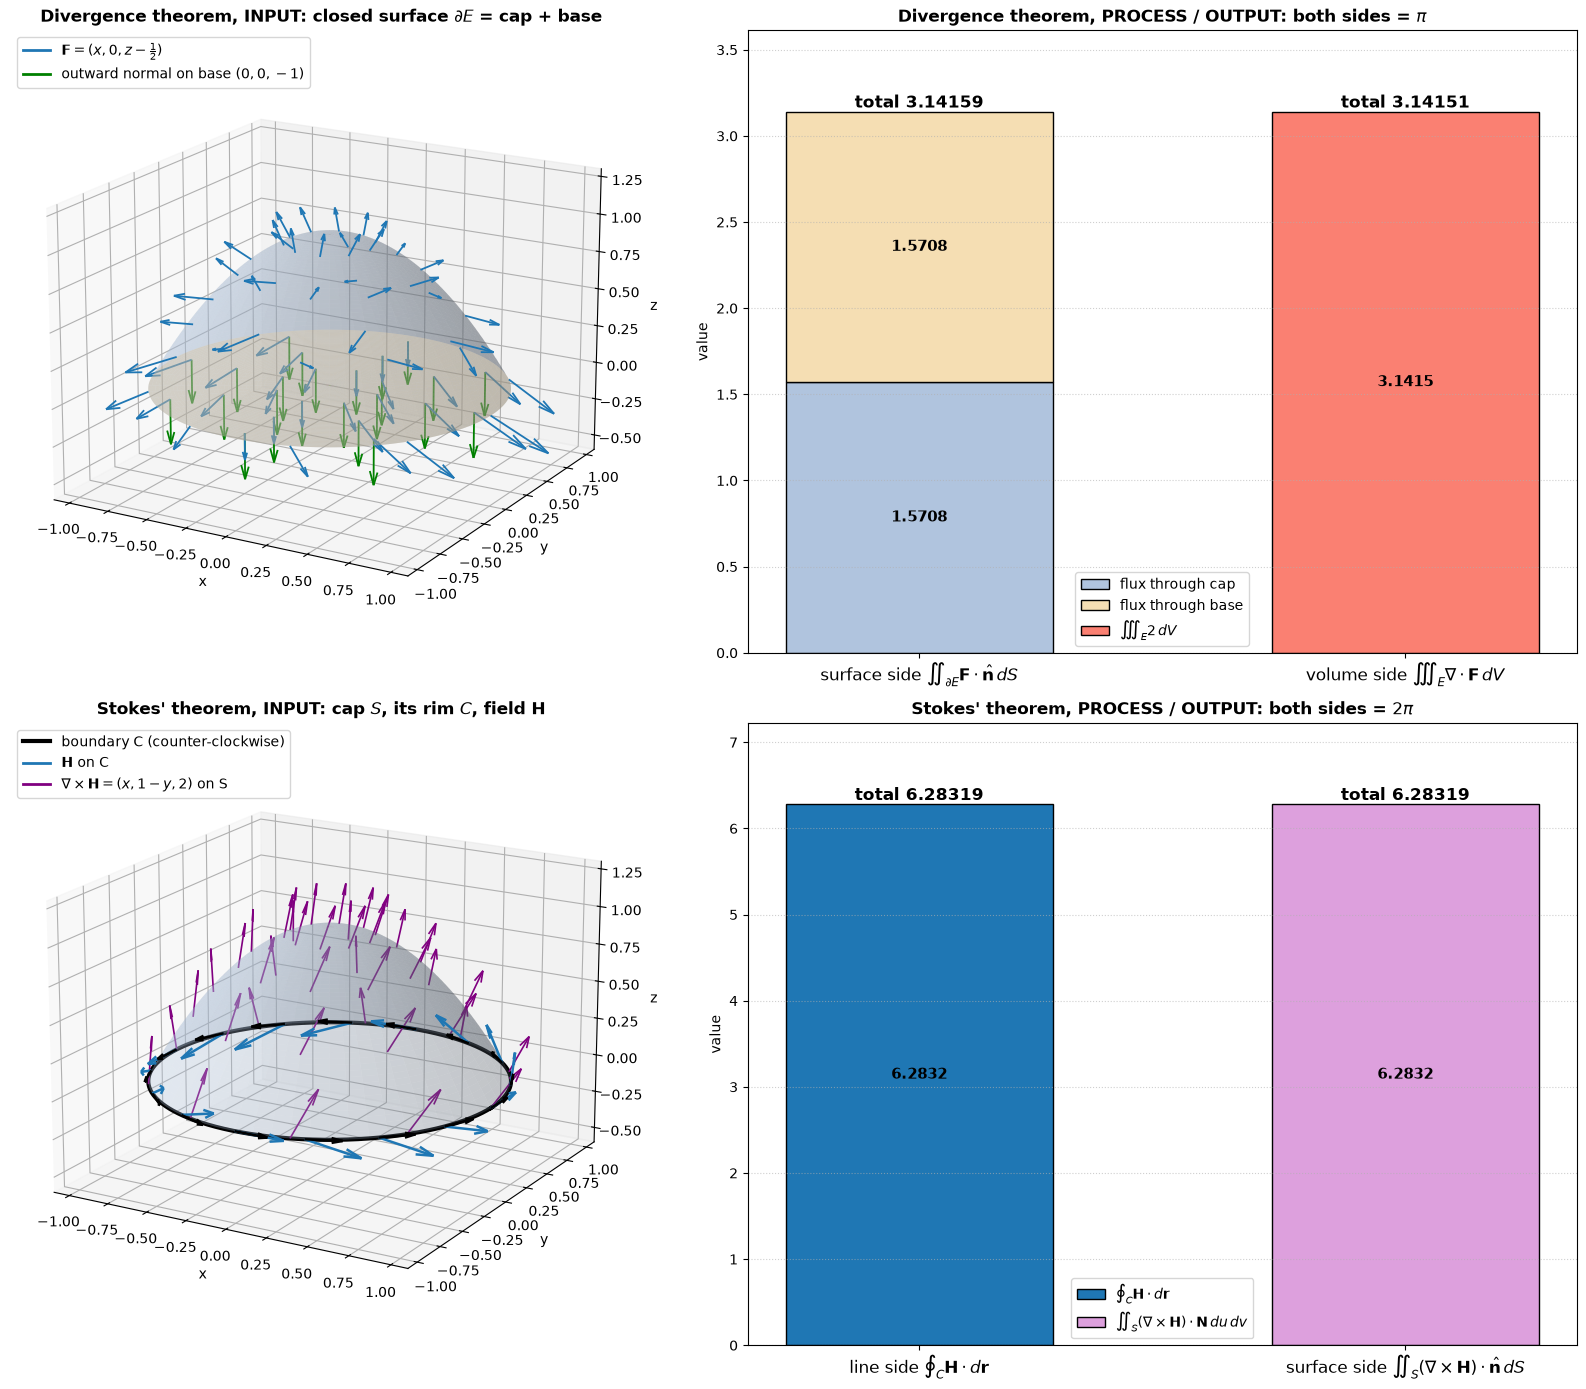

In [6]:
# 5. INTEGRAL THEOREMS on the paraboloid solid
#   Divergence: flux out of the closed surface = iiint div F dV
#   Stokes:     circulation around the rim     = iint (curl H) . n dS over the cap

import numpy as np
import matplotlib.pyplot as plt

trap = getattr(np, 'trapezoid', None) or getattr(np, 'trapz')

# Cap S: r(u, v) = (u cos v, u sin v, 1 - u^2), N = r_u x r_v = (2u^2 cos v, 2u^2 sin v, u) (upward / outward)
u = np.linspace(0, 1, 201)
v = np.linspace(0, 2 * np.pi, 241)
U, V = np.meshgrid(u, v)
X, Y, Z = U * np.cos(V), U * np.sin(V), 1 - U**2
Nx, Ny, Nz = 2 * U**2 * np.cos(V), 2 * U**2 * np.sin(V), U


def iint(fv):
    return trap(trap(fv, u, axis=1), v)


# ---------------- DIVERGENCE THEOREM: F = (x, 0, z - 1/2), div F = 2 ----------------
flux_cap = iint(X * Nx + (Z - 0.5) * Nz)
# Base disc z = 0: r(u, v) = (u cos v, u sin v, 0), outward normal points down: N = (0, 0, -u)
flux_base = iint((0 - 0.5) * (-U))
# Volume side in cylindrical coordinates: iiint 2 dV = int int 2 (1 - r^2) r dr dtheta
vol_side = iint(2 * (1 - U**2) * U)

# ---------------- STOKES' THEOREM: H = (z - y, x, xy), curl H = (x, 1 - y, 2) ----------------
t = np.linspace(0, 2 * np.pi, 2001)
cx, cy, cz = np.cos(t), np.sin(t), np.zeros_like(t)
dcx, dcy = -np.sin(t), np.cos(t)
line_side = trap((cz - cy) * dcx + cx * dcy, t)               # dz = 0 on the rim
curl_dot_N = X * Nx + (1 - Y) * Ny + 2 * Nz
surf_side = iint(curl_dot_N)

print("--- DIVERGENCE THEOREM ---")
print(f"flux through cap  = {flux_cap:.6f}   (exact pi/2)")
print(f"flux through base = {flux_base:.6f}   (exact pi/2)")
print(f"closed-surface flux = {flux_cap + flux_base:.6f}")
print(f"iiint div F dV      = {vol_side:.6f}   (exact pi = {np.pi:.6f})")
print("--- STOKES' THEOREM ---")
print(f"circulation around C  = {line_side:.6f}")
print(f"iint (curl H) . n dS  = {surf_side:.6f}   (exact 2 pi = {2 * np.pi:.6f})")

# --- Visualization ---
fig = plt.figure(figsize=(17, 14))
iu, iv = np.array([50, 100, 150, 200]), np.arange(0, 240, 24)
Pu, Pv = np.meshgrid(iu, iv)
bu, bv = np.meshgrid(np.linspace(0.3, 0.9, 3), np.linspace(0, 2 * np.pi, 9)[:-1])
bx, by = bu * np.cos(bv), bu * np.sin(bv)


def style3d(ax, title):
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_zlim(-0.6, 1.3)
    ax.view_init(elev=18, azim=-60)
    ax.set_title(title, fontsize=12, fontweight='bold')


def bars(ax, labels, stacks, colors, title, ylabel):
    for i, stack in enumerate(stacks):
        bottom = 0
        for (lab, val), col in zip(stack, colors[i]):
            ax.bar(i, val, bottom=bottom, color=col, edgecolor='k', width=0.55, label=lab)
            ax.text(i, bottom + val / 2, f'{val:.4f}', ha='center', va='center', fontsize=11, fontweight='bold')
            bottom += val
        ax.text(i, bottom, f'total {bottom:.5f}', ha='center', va='bottom', fontsize=12, fontweight='bold')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=12)
    ax.set_ylabel(ylabel)
    ax.margins(y=0.15)
    ax.legend(loc='lower center', fontsize=10)
    ax.grid(True, axis='y', linestyle=':', alpha=0.6)
    ax.set_title(title, fontsize=12, fontweight='bold')


# Divergence: INPUT
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
ax1.plot_surface(X, Y, Z, color='lightsteelblue', alpha=0.3, edgecolor='none', rstride=4, cstride=4)
ax1.plot_surface(U * np.cos(V), U * np.sin(V), 0 * U, color='wheat', alpha=0.4, edgecolor='none', rstride=4, cstride=4)
sx, sy, sz = X[Pv, Pu], Y[Pv, Pu], Z[Pv, Pu]
ax1.quiver(sx, sy, sz, sx, 0 * sx, sz - 0.5, length=0.35, color='tab:blue', linewidth=1.3)
ax1.quiver(bx, by, 0 * bx, bx, 0 * bx, 0 * bx - 0.5, length=0.35, color='tab:blue', linewidth=1.3)
ax1.quiver(bx, by, 0 * bx, 0 * bx, 0 * bx, -np.ones_like(bx), length=0.3, color='green', linewidth=1.3)
ax1.plot([], [], color='tab:blue', lw=2, label=r'$\mathbf{F} = (x, 0, z - \frac{1}{2})$')
ax1.plot([], [], color='green', lw=2, label=r'outward normal on base $(0, 0, -1)$')
ax1.legend(loc='upper left')
style3d(ax1, r'Divergence theorem, INPUT: closed surface $\partial E$ = cap + base')

# Divergence: PROCESS -> OUTPUT
ax2 = fig.add_subplot(2, 2, 2)
bars(ax2, [r'surface side $\iint_{\partial E}\mathbf{F}\cdot\hat{\mathbf{n}}\,dS$',
           r'volume side $\iiint_E \nabla\cdot\mathbf{F}\,dV$'],
     [[('flux through cap', flux_cap), ('flux through base', flux_base)],
      [(r'$\iiint_E 2\, dV$', vol_side)]],
     [['lightsteelblue', 'wheat'], ['salmon']],
     'Divergence theorem, PROCESS / OUTPUT: both sides = $\\pi$', 'value')

# Stokes: INPUT
ax3 = fig.add_subplot(2, 2, 3, projection='3d')
ax3.plot_surface(X, Y, Z, color='lightsteelblue', alpha=0.3, edgecolor='none', rstride=4, cstride=4)
ax3.plot(cx, cy, cz, 'k-', lw=3)
k = np.arange(0, 2000, 125)
ax3.quiver(cx[k], cy[k], cz[k], cz[k] - cy[k], cx[k], cx[k] * cy[k], length=0.3, color='tab:blue', linewidth=1.8)
ax3.quiver(cx[k], cy[k], cz[k], dcx[k], dcy[k], 0 * k, length=0.2, color='k', linewidth=1.8)
ax3.quiver(sx, sy, sz, sx, 1 - sy, 2 * np.ones_like(sx), length=0.12, color='purple', linewidth=1.2)
ax3.plot([], [], 'k-', lw=3, label='boundary C (counter-clockwise)')
ax3.plot([], [], color='tab:blue', lw=2, label=r'$\mathbf{H}$ on C')
ax3.plot([], [], color='purple', lw=2, label=r'$\nabla\times\mathbf{H} = (x, 1 - y, 2)$ on S')
ax3.legend(loc='upper left')
style3d(ax3, r"Stokes' theorem, INPUT: cap $S$, its rim $C$, field $\mathbf{H}$")

# Stokes: PROCESS -> OUTPUT
ax4 = fig.add_subplot(2, 2, 4)
bars(ax4, [r'line side $\oint_C \mathbf{H}\cdot d\mathbf{r}$',
           r'surface side $\iint_S (\nabla\times\mathbf{H})\cdot\hat{\mathbf{n}}\,dS$'],
     [[(r'$\oint_C \mathbf{H}\cdot d\mathbf{r}$', line_side)],
      [(r'$\iint_S (\nabla\times\mathbf{H})\cdot\mathbf{N}\,du\,dv$', surf_side)]],
     [['tab:blue'], ['plum']],
     "Stokes' theorem, PROCESS / OUTPUT: both sides = $2\\pi$", 'value')

plt.tight_layout()
plt.show()